## 1. Import & Load data

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dython.nominal import associations
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score

from ml_challenge.config import RAW_DATA_DIR

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

In [8]:
df_train = pd.read_csv(RAW_DATA_DIR / "train.csv")
df_test = pd.read_csv(RAW_DATA_DIR / "test.csv")

print(f'Train shape: {df_train.shape}')
print(f'Test shape: {df_test.shape}')

Train shape: (699960, 26)
Test shape: (299984, 25)


## 2. Dataset Overview

In [2]:
#df_train.head(10)
df_train.sample(5, random_state=42)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
451125,451125,31.47,8.51,3,18.73,55,56,699.40,0,0.0,...,OTP,Online,POS Terminal,False,False,False,False,False,False,0.0
370124,370124,10.07,4.65,7,1.96,48,24,677.78,0,24.6,...,PIN,Online,Android Phone,False,False,False,False,False,False,0.0
504395,504395,37.79,4.16,4,16.86,54,37,764.18,0,0.0,...,OTP,In-App,iPhone,False,False,False,False,False,False,0.0
103461,103461,50.59,6.21,2,2.57,53,53,921.48,0,15.0,...,3D Secure,POS,POS Terminal,False,False,False,False,False,False,0.0
670980,670980,22.74,7.52,1,0.89,50,49,3022.38,0,0.0,...,No Authentication,Contactless,iPhone,False,False,False,False,False,False,0.0


In [3]:
# schema
df_train.info(memory_usage=True)

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [4]:
# Numeric describe
df_train.drop(axis=1, labels=["id"]).describe().T

,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90
time_of_day_hour,699960.0,11.761915,6.869164,0.00,6.00,12.00,18.00,23.00


In [10]:
num_cols = df_train.select_dtypes(include=["float64", "int64"]).columns.to_list()
cat_cols = df_train.select_dtypes(include=["str"]).columns.to_list()
bool_cols = df_train.select_dtypes(include=["bool"]).columns.to_list()

# remove id and target from feature list
num_cols = [c for c in num_cols if c not in ["id", "is_fraud"]]

print(f"Numerical columns: ({len(num_cols)}): {num_cols}")
print(f"Categorical columns: ({len(cat_cols)}): {cat_cols}")
print(f"Binary columns: ({len(bool_cols)}): {bool_cols}")

Numerical columns: (13): ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']
Categorical columns: (5): ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
Binary columns: (6): ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


## 3. Analyze the Target variable

In [11]:
target = df_train["is_fraud"]
print(f"Unique values: {target.unique()}") # 2 values: 0.0 and 1.0

target_vcount = target.value_counts()
target_vpct = target.value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_vcount,
    "Percentage (%)": target_vpct.round(2)
})
print(target_summary)

Unique values: [0. 1.]
           Count  Percentage (%)
is_fraud                        
0.0       688271           98.33
1.0        11689            1.67


In [7]:
# strongly imbalance 
# potential problem: model is biased towards 'not_fraud', so "Accuracy" alone is not enough

# 4. Numerical Feature Analysis

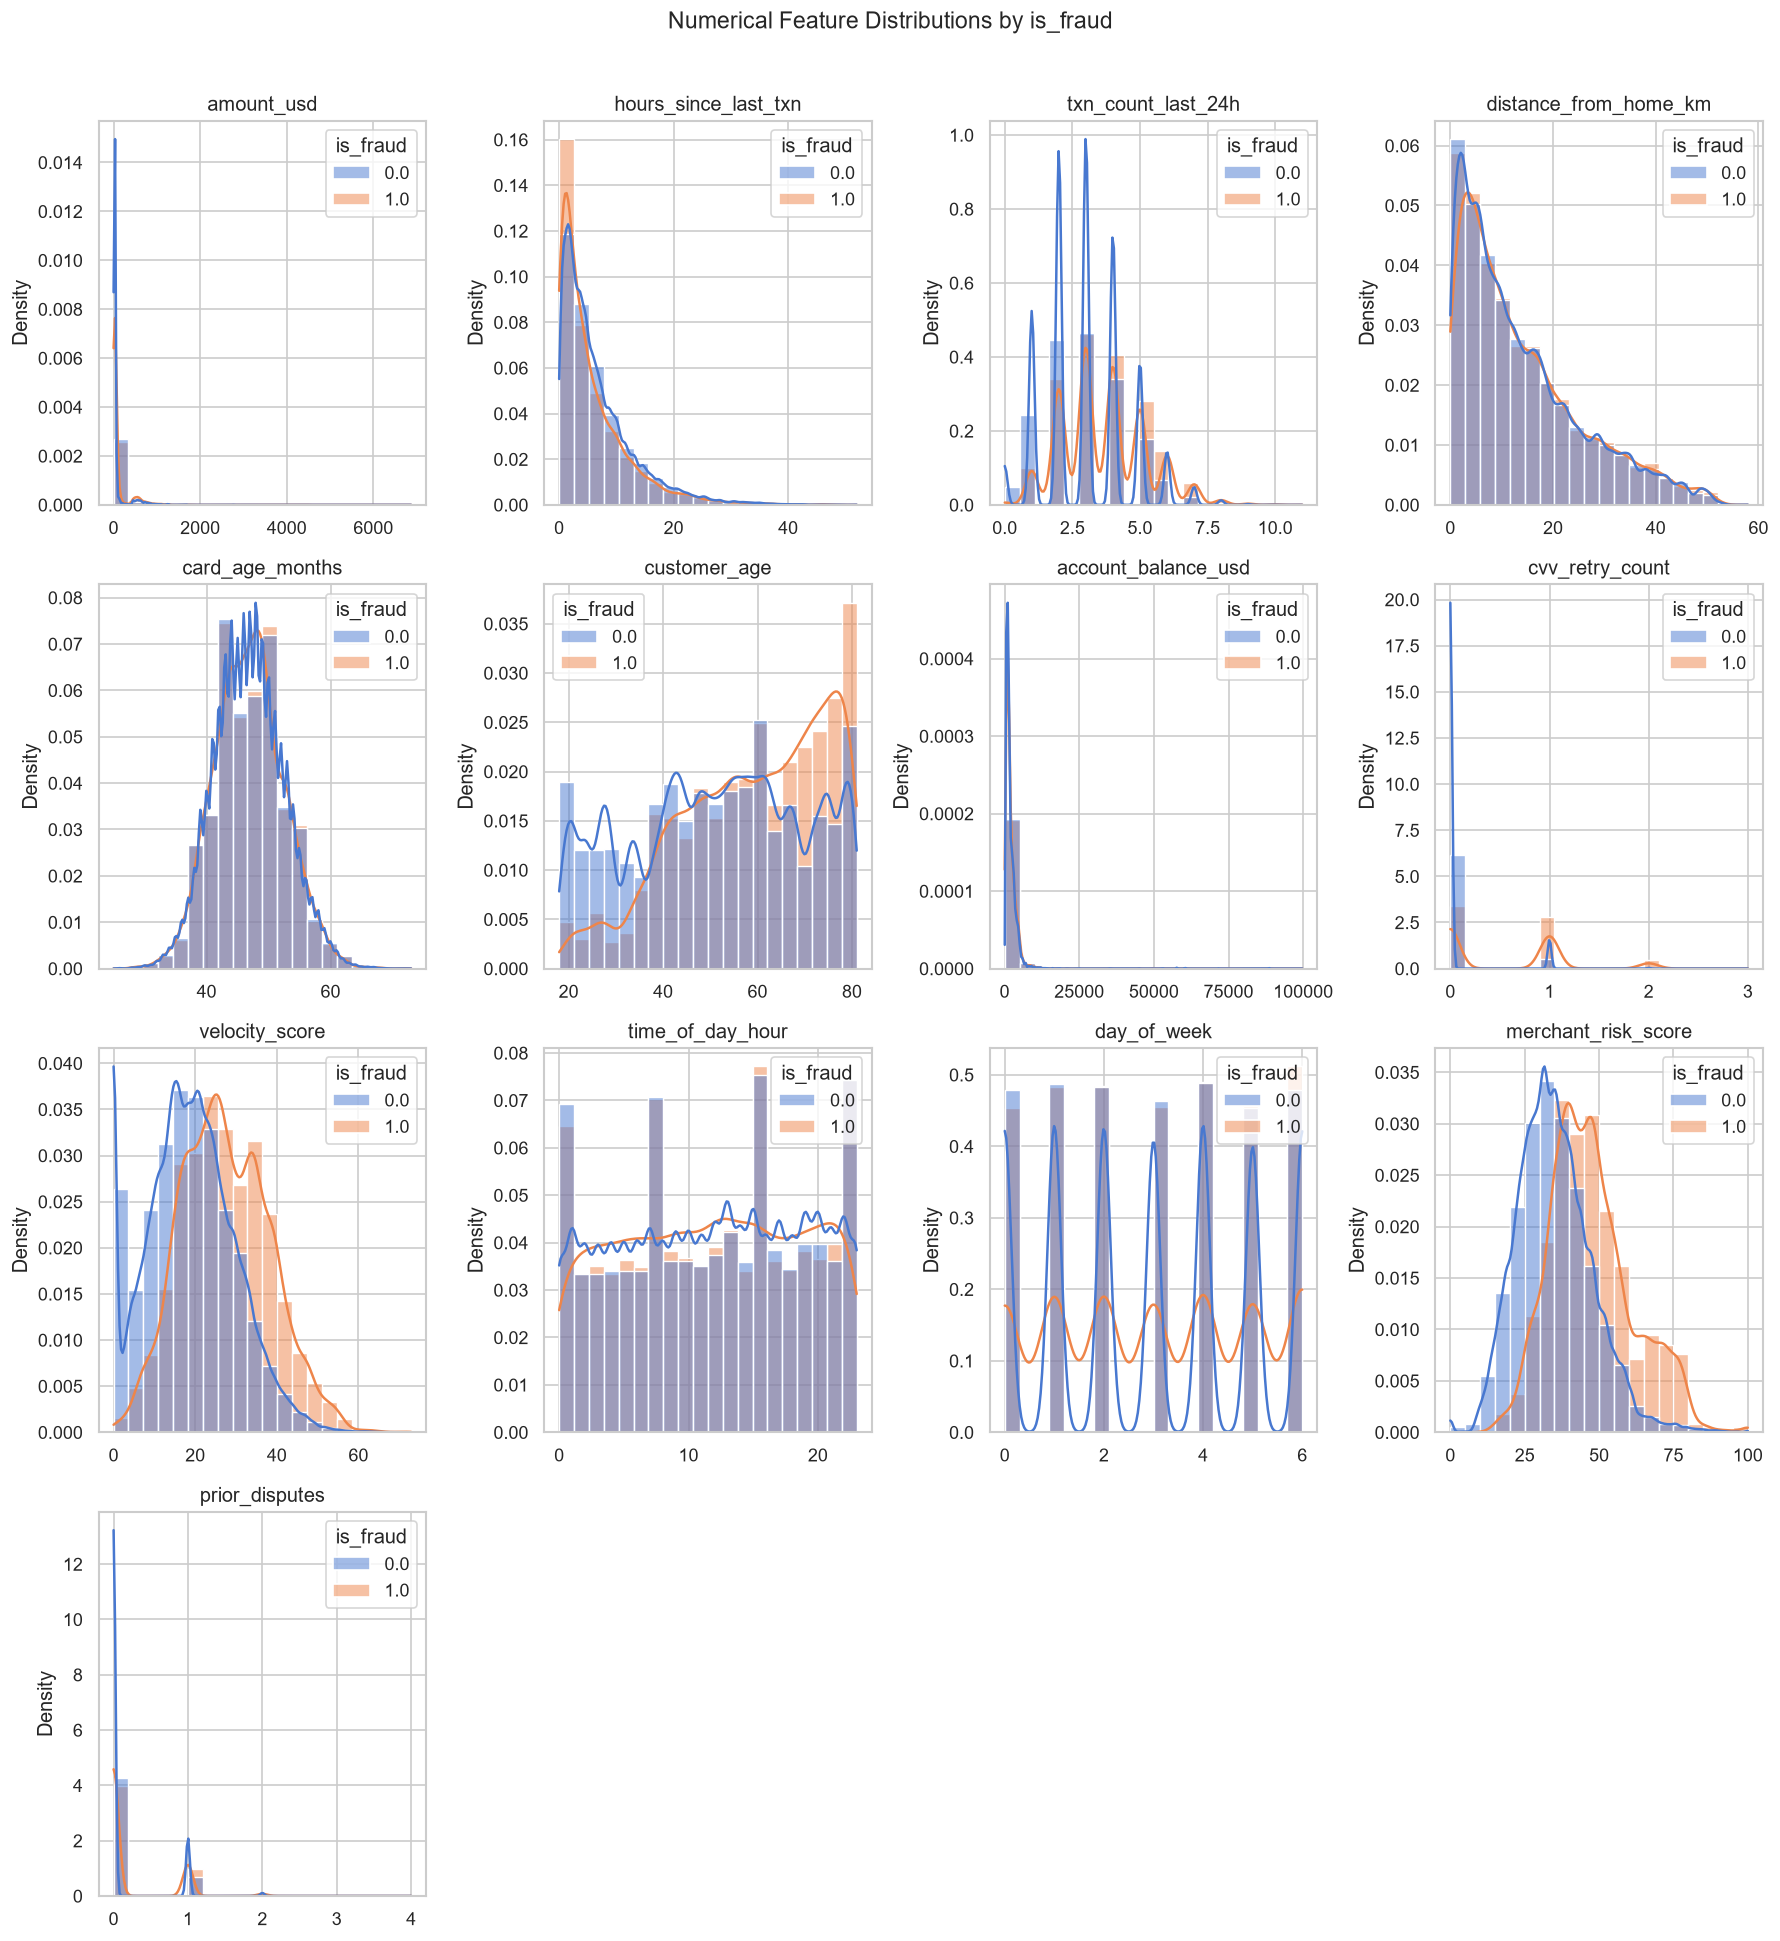

In [12]:
# Distribution of each numercial feature
n_cols = 4
n_rows = int(np.ceil(len(num_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df_train, x=col, hue='is_fraud', stat="density", common_norm=False, kde=True, ax=axes[i], bins=20)
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel('')

# Hide unused axes
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numerical Feature Distributions by is_fraud', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

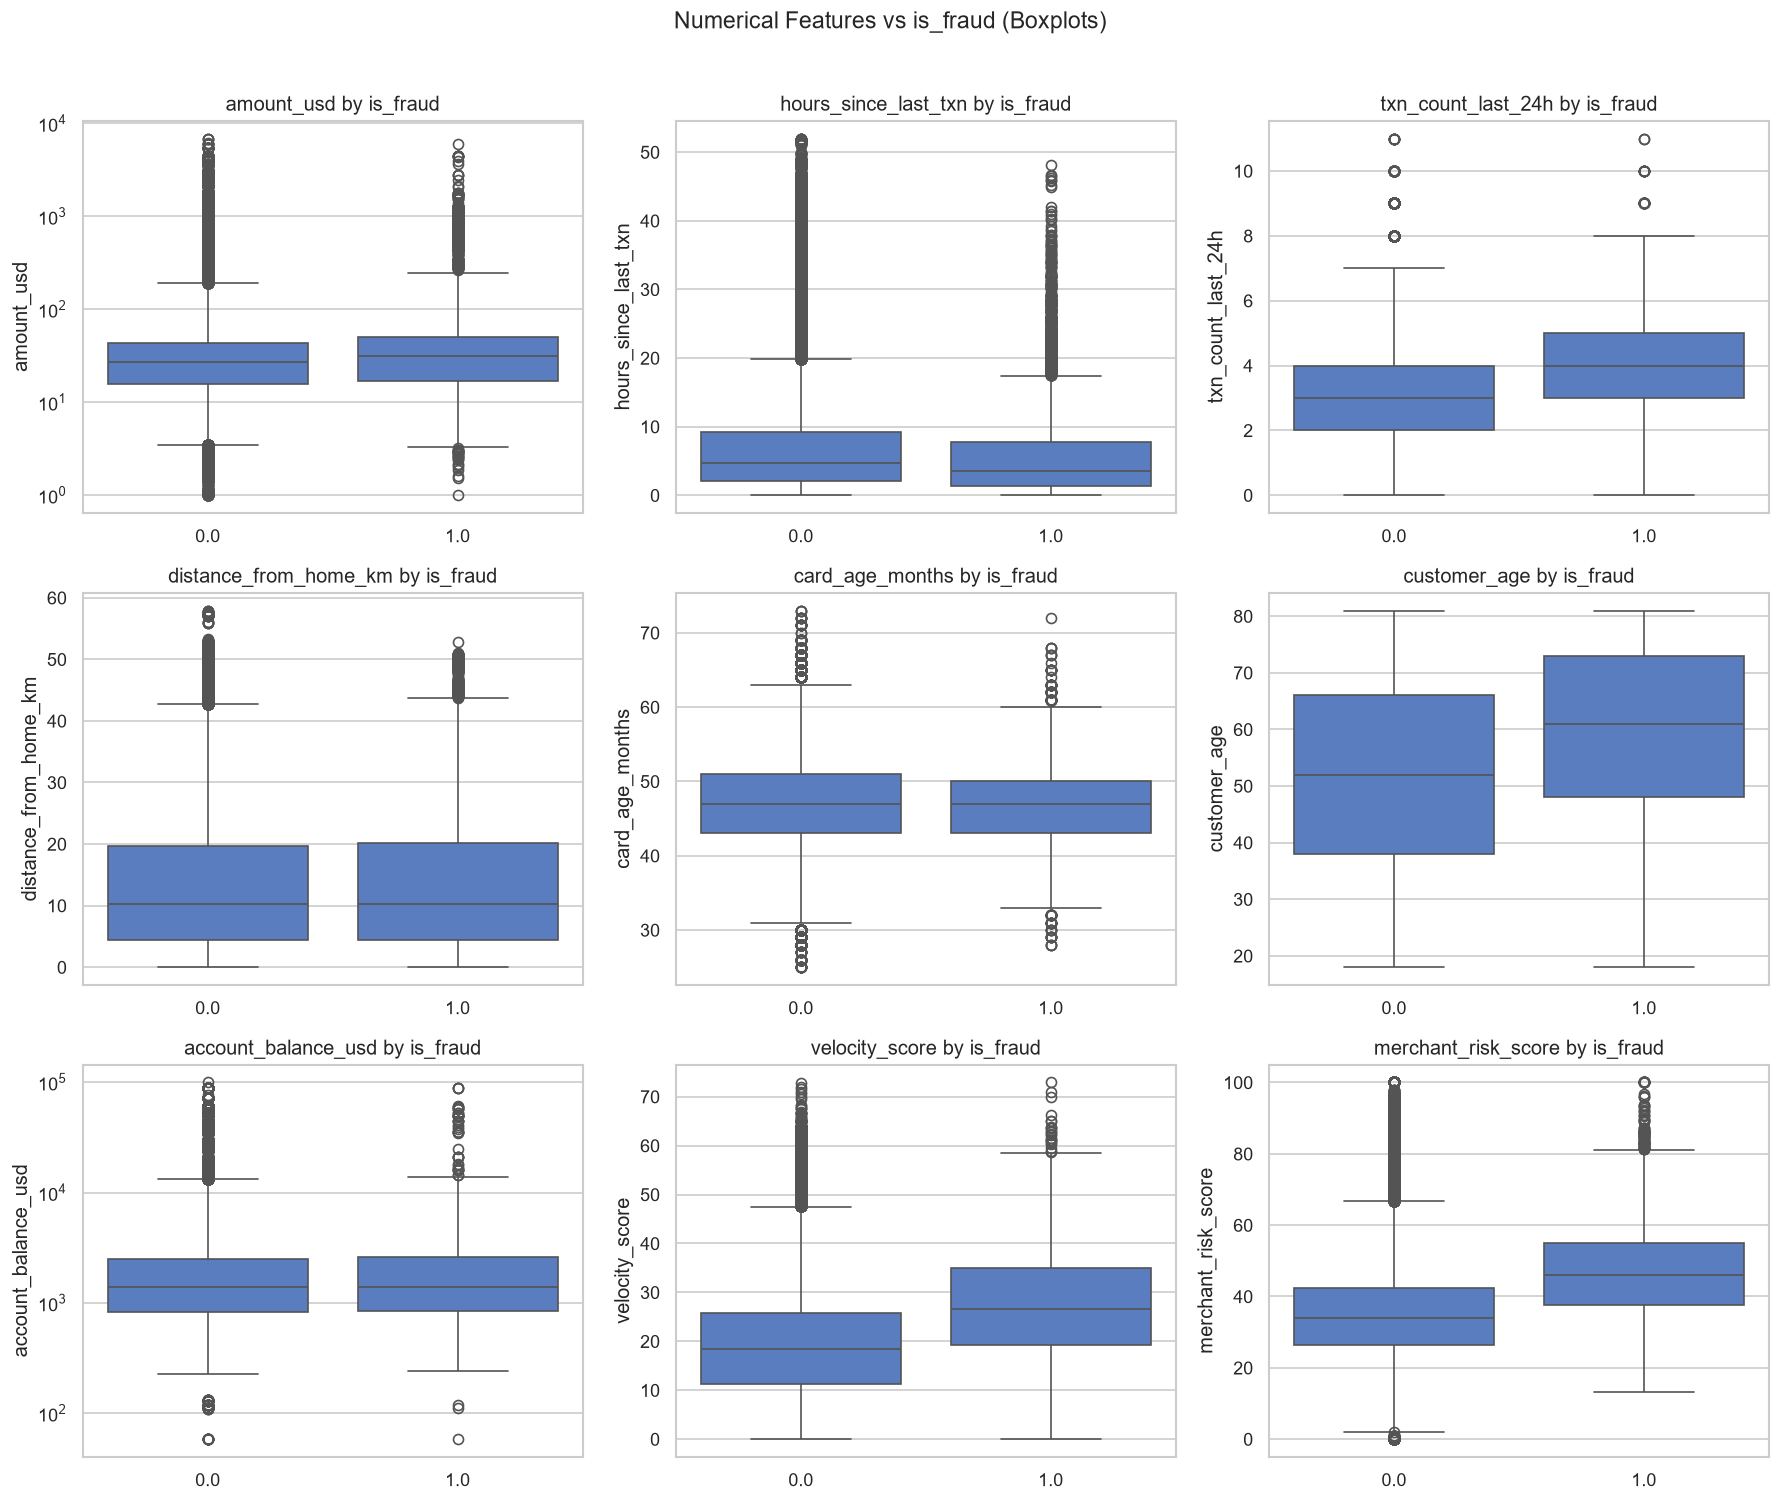

In [13]:
# Box plots: See spread, potential outliers
box_n_cols = 3
box_n_rows = 4
fig, axes = plt.subplots(box_n_rows, box_n_cols, figsize=(15, box_n_rows * 4))
axes = axes.flatten()
# skip some features
skip_box_cols = ['cvv_retry_count', 'time_of_day_hour', 'day_of_week', 'prior_disputes']
box_cols = [c for c in num_cols if c not in skip_box_cols]

for i, col in enumerate(box_cols):
    if col in ["amount_usd", "account_balance_usd"]:
        axes[i].set_yscale("log")
    sns.boxplot(data=df_train, x='is_fraud', y=col, ax=axes[i])
    axes[i].set_title(f'{col} by is_fraud')
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numerical Features vs is_fraud (Boxplots)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [11]:
# investigate amount_usd and account_balance_usd
df_train.groupby("is_fraud")[["amount_usd", "account_balance_usd"]].mean()

,amount_usd,account_balance_usd
is_fraud,,
0.0,79.373189,2064.520948
1.0,110.504532,2093.091944


In [12]:
df_train.groupby("is_fraud")[["amount_usd", "account_balance_usd"]].quantile([0.25, 0.5, 0.75])

amount_usd  account_balance_usd
is_fraud                                      
0.0      0.25       15.77               834.02
         0.50       27.21              1382.74
         0.75       42.95              2516.25
1.0      0.25       16.77               841.36
         0.50       31.18              1396.00
         0.75       49.89              2611.10

central distributions (central tendency) of these 2 features (by `is_fraud`) are mostly the same. 
This indicates that based on a that single feature and the interquartile range (IQR) alone, the two classes (not or is_fraud) show significant overlap and are difficult to separate.  
May have signal at the extremes, or when combine with other feature(s) 

potential numerical features:
```text
merchant_risk_score
velocity_score          # (maybe) the speed of txn made
hours_since_last_txn
txn_count_last_24h
cvv_retry_count
customer_age
```

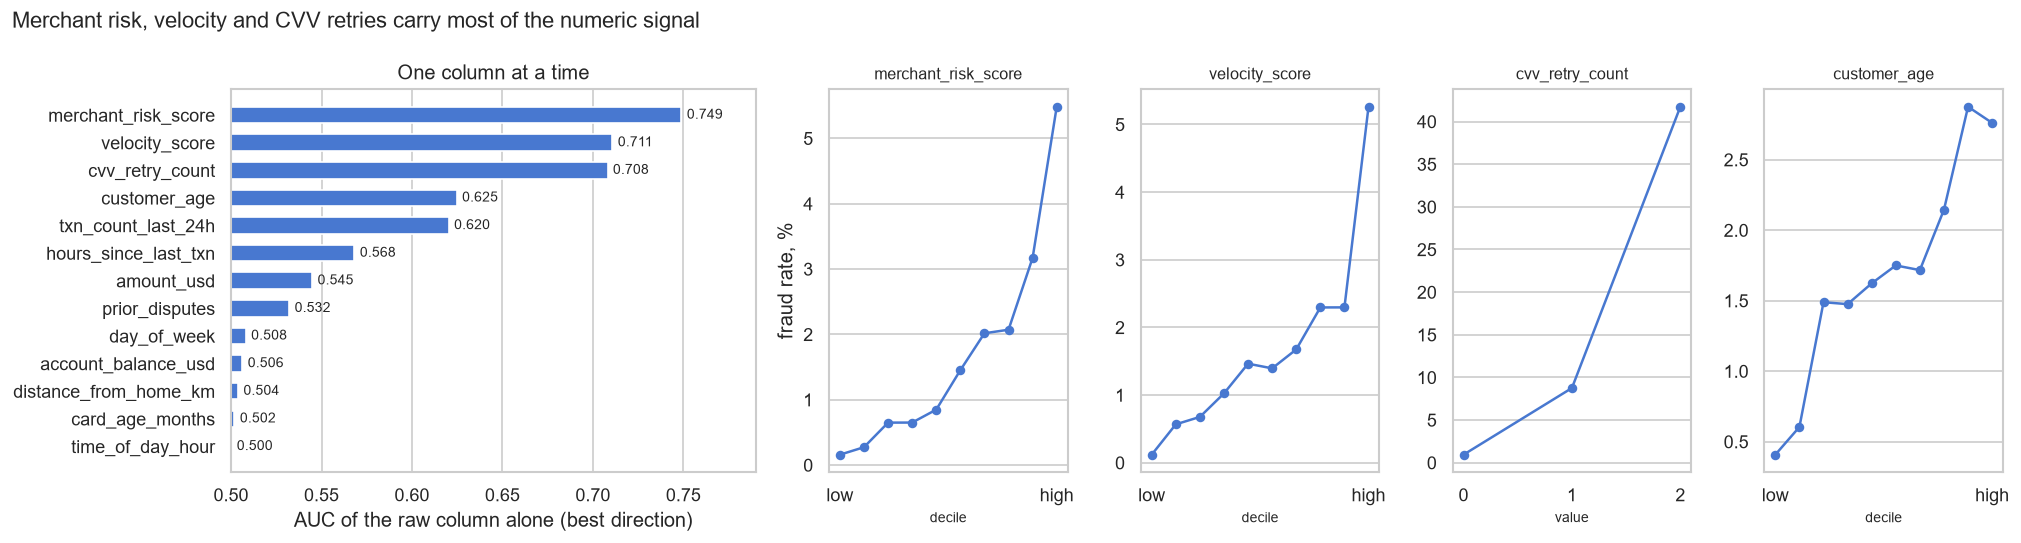

In [14]:
# original code from https://www.kaggle.com/code/yashteotia/s6e11-beginner-expert-lb-0-95306?scriptVersionId=368074474&cellId=12

y = df_train["is_fraud"].astype(int).to_numpy()
uni = pd.Series({c: max(roc_auc_score(y, df_train[c]), 1 - roc_auc_score(y, df_train[c])) for c in num_cols}).sort_values()

fig = plt.figure(figsize=(17, 4.6))
grid = fig.add_gridspec(1, 5, width_ratios=[2.2, 1, 1, 1, 1])
axes = fig.add_subplot(grid[0])
axes.barh(uni.index, uni.values - 0.5, left=0.5, height=0.6)
for i, v in enumerate(uni.values):
    axes.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8.5)
axes.set_xlim(0.5, 0.79)
axes.set_xlabel("AUC of the raw column alone (best direction)")
axes.grid(axis="y", visible=False)
axes.set_title("One column at a time")

top4 = uni.index[::-1][:4]
for k, col in enumerate(top4):
    a = fig.add_subplot(grid[k + 1])
    groups = df_train[col] if df_train[col].nunique() <= 12 else pd.qcut(df_train[col], 10, duplicates="drop")
    g = df_train.groupby(groups, observed=True)["is_fraud"].agg(["mean", "size"])
    g = g[g["size"] >= 500]
    a.plot(range(len(g)), g["mean"] * 100, marker="o", markersize=4.5, markeredgewidth=1.2)
    a.set_title(col, fontsize=9.5)
    a.set_xlabel("value" if df_train[col].nunique() <= 12 else "decile", fontsize=8.5)
    if df_train[col].nunique() <= 12:
        a.set_xticks(range(len(g)), [str(int(v)) for v in g.index])
    else:
        a.set_xticks([0, len(g) - 1], ["low", "high"])
    a.grid(axis="x", visible=False)
    if k == 0:
        a.set_ylabel("fraud rate, %")
fig.suptitle("Merchant risk, velocity and CVV retries carry most of the numeric signal", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

> The AUC Score, also known as the Area Under the Curve, is a score measured by 
> calculating the area under the Receiver Operating Characteristic (ROC) Curve.

_Plots true pos rate/false pos rate_

In [35]:
display(df_train.groupby("cvv_retry_count")["is_fraud"].agg(
    fraud_rate="mean",
    rows="size"
).style.format({"fraud_rate": "{:.2%}", "rows": "{:,}"}))

,fraud_rate,rows
cvv_retry_count,,
0,0.93%,"642,088"
1,8.75%,"55,942"
2,41.73%,"1,905"
3,36.00%,25



Single feature signal:  

`merchant_risk_score`, `velocity_score` and `cvv_retry_count` stand out,  
then `customer_age` and `txn_count_last_24h`

## 5. Categorical Feature Analysis

In [13]:
for col in cat_cols:
    print(f"{col}: {df_train[col].nunique()} unique values => {df_train[col].unique().tolist()}")

merchant_category: 12 unique values => ['Groceries', 'Online Retail', 'Utilities', 'Electronics', 'Healthcare', 'Restaurants', 'Fuel', 'Streaming', 'Crypto Exchange', 'Gaming', 'Travel', 'Gift Cards']
card_type: 5 unique values => ['Mastercard', 'Visa', 'Amex', 'RuPay', 'Discover']
auth_method: 5 unique values => ['OTP', 'PIN', '3D Secure', 'Biometric', 'No Authentication']
channel: 5 unique values => ['POS', 'In-App', 'Online', 'ATM', 'Contactless']
device_type: 8 unique values => ['iPhone', 'Android Phone', 'Tablet', 'Windows PC', 'POS Terminal', 'Mac', 'ATM Machine', 'Smart Watch']


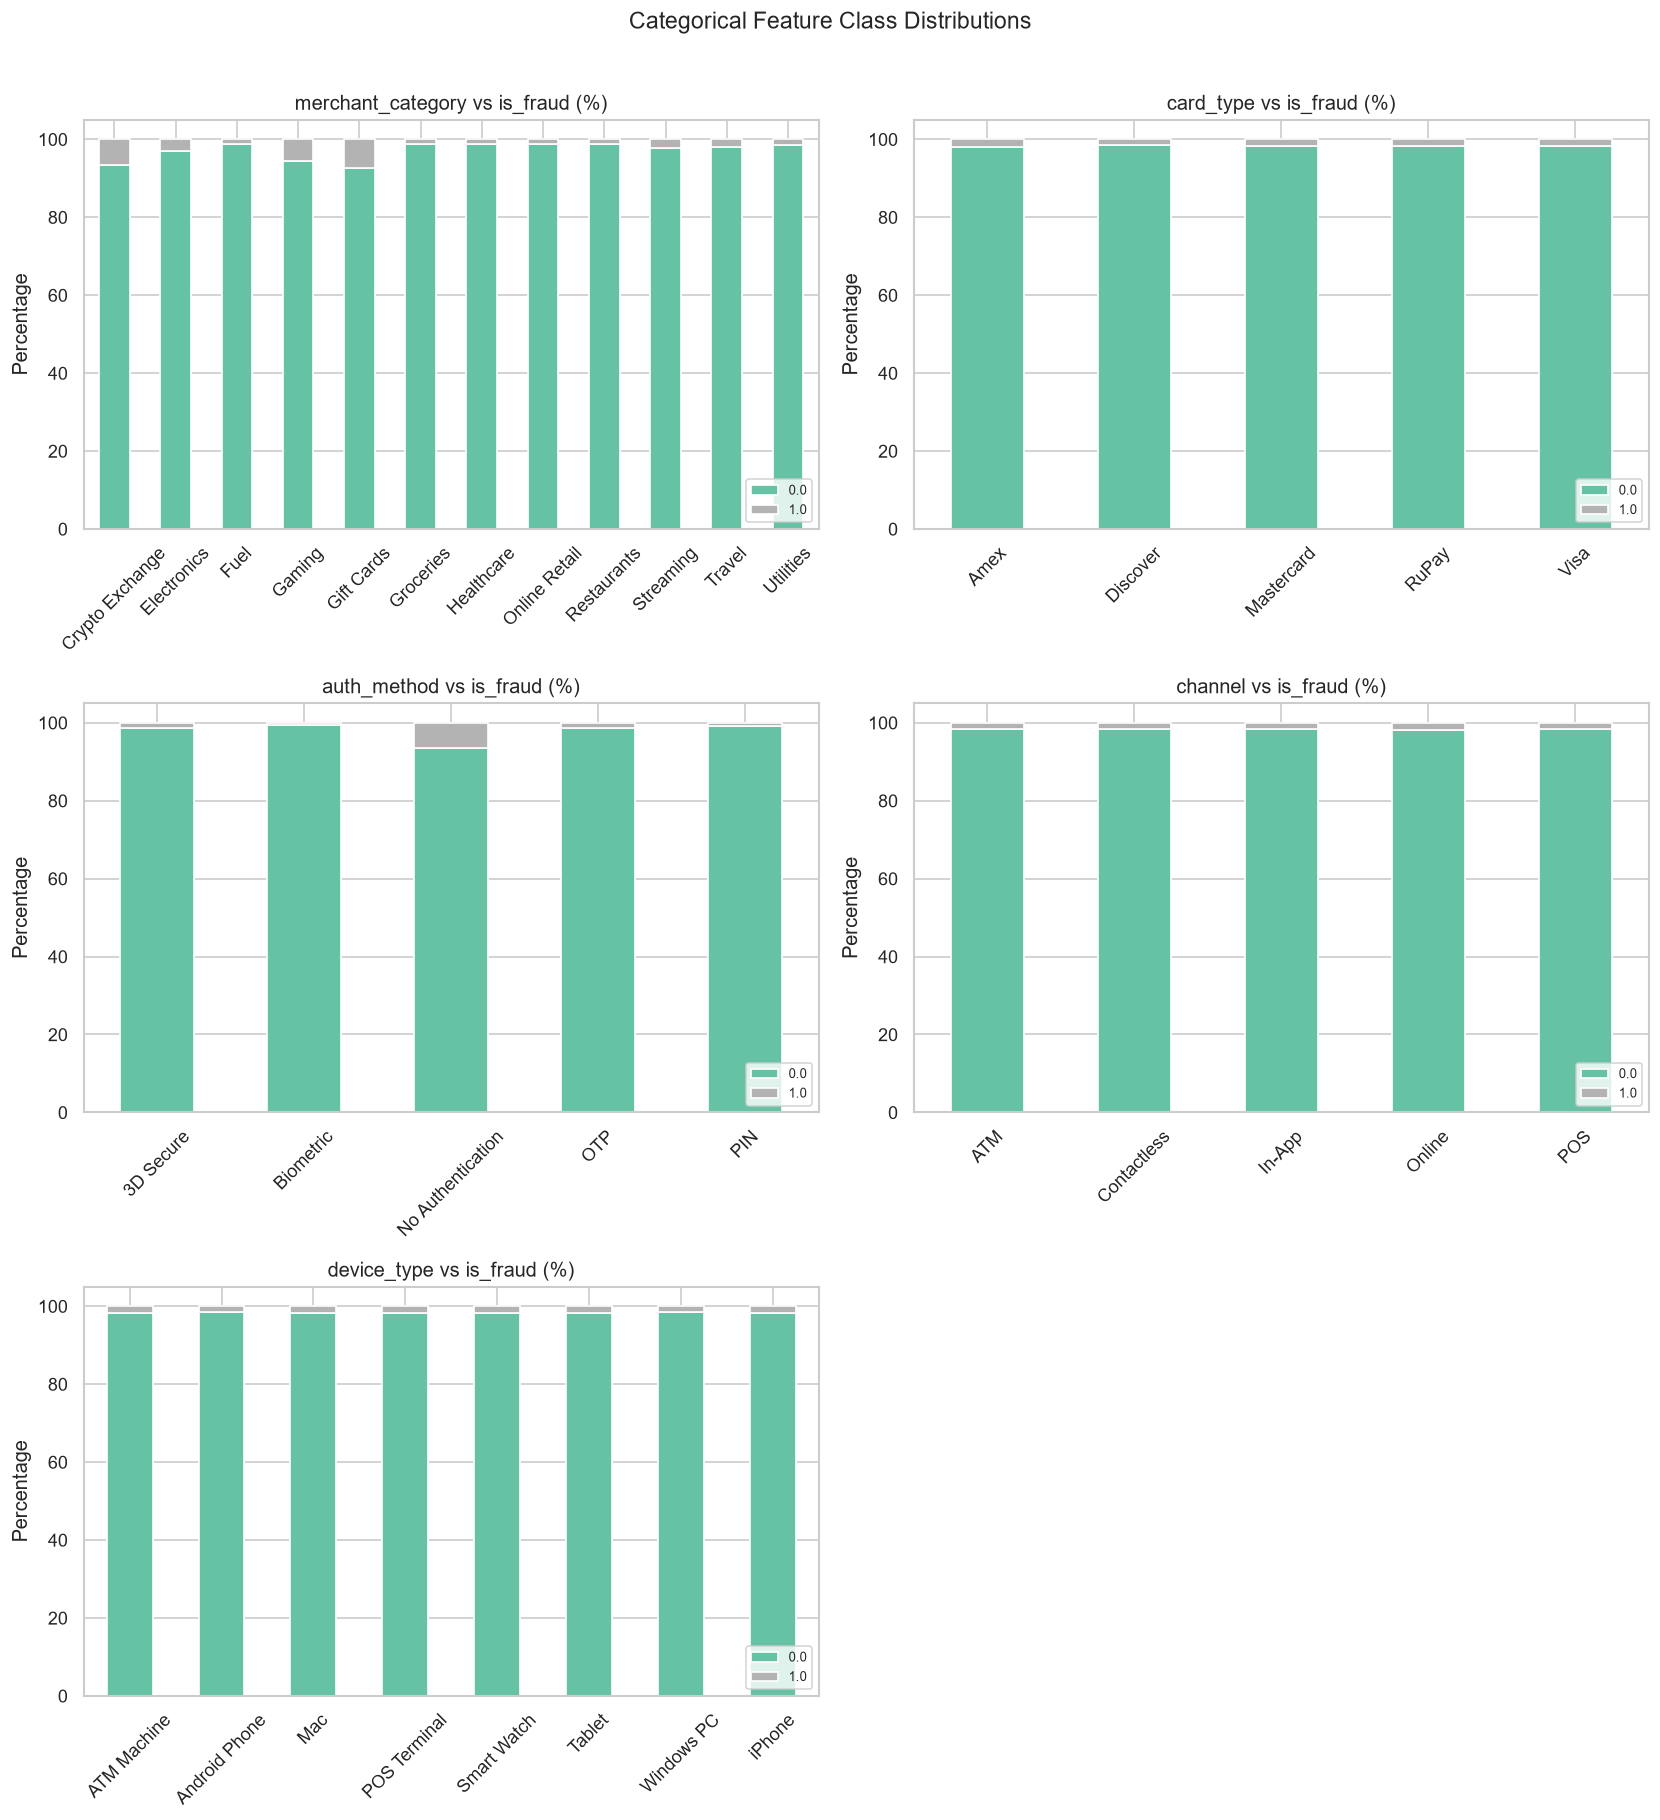

In [15]:
n_cols_plot = 2
n_rows_plot = int(np.ceil(len(cat_cols) / n_cols_plot))

fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(14, n_rows_plot * 5))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    ct = pd.crosstab(df_train[col], df_train["is_fraud"], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, ax=axes[i], colormap='Set2')
    axes[i].set_title(f'{col} vs is_fraud (%)')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Percentage')
    axes[i].legend(loc='lower right', fontsize=8)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Categorical Feature Class Distributions', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

Prominent categorical features **associated to** fraud detection:
- merchant_category: Crypto Exchange, Gift card, Gaming
- auth_method: No Authentication

We are not sure if these categories and others actually have some kind of correlation. (Do they usually appear side by side, or interacts/influences each other, redundant, ....)

In [16]:
def fraud_rate_by_features(features, train):
    for feat in features:
        summary = train.groupby(feat)["is_fraud"].agg(
            total="count",      # total txn
            fraud="sum",        # total fraud txn
            fraud_rate="mean"   # fraud rate, of all categorical features
        )
        summary["fraud_rate"] *= 100
        display(summary.sort_values("fraud_rate", ascending=False))

prominent_cat_feat = ["merchant_category", "auth_method"]
fraud_rate_by_features(prominent_cat_feat, df_train) # test assumption, they matter

,total,fraud,fraud_rate
merchant_category,,,
Gift Cards,9456,690.0,7.296954
Crypto Exchange,5285,345.0,6.527909
Gaming,23784,1311.0,5.512109
Electronics,48693,1501.0,3.082579
Streaming,47196,1061.0,2.248072
Travel,28715,534.0,1.859655
Utilities,42027,581.0,1.382445
Healthcare,35889,462.0,1.287303
Fuel,59880,741.0,1.237475


,total,fraud,fraud_rate
auth_method,,,
No Authentication,67060,4322.0,6.444975
3D Secure,210036,3098.0,1.474985
OTP,175178,2464.0,1.406569
PIN,154020,1337.0,0.868069
Biometric,93666,468.0,0.499648


Bool features exploration

In [17]:
fraud_rate_by_features(bool_cols, df_train)

,total,fraud,fraud_rate
is_foreign_transaction,,,
True,12098,1521.0,12.572326
False,687862,10168.0,1.478203


,total,fraud,fraud_rate
is_new_merchant,,,
True,106720,5052.0,4.733883
False,593240,6637.0,1.118771


,total,fraud,fraud_rate
used_vpn,,,
True,23665,1550.0,6.549757
False,676295,10139.0,1.499198


,total,fraud,fraud_rate
ip_country_mismatch,,,
True,11312,1866.0,16.495757
False,688648,9823.0,1.426418


,total,fraud,fraud_rate
billing_shipping_mismatch,,,
True,9054,1176.0,12.988734
False,690906,10513.0,1.521625


,total,fraud,fraud_rate
is_ai_generated_scam_attempt,,,
True,2299,350.0,15.224010
False,697661,11339.0,1.625288


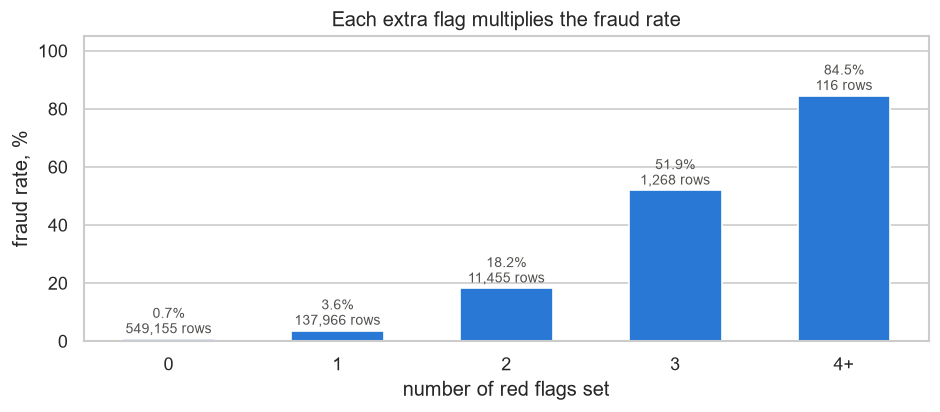

In [18]:
# RED FLAGS / Txn;  
n_flags = df_train[bool_cols].sum(axis=1).clip(upper=4)
flags = df_train.groupby(n_flags)["is_fraud"].agg(["mean", "size"])
flags.index = [str(i) if i < 4 else "4+" for i in flags.index]

fig, axes = plt.subplots(figsize=(8, 3.6))
axes.bar(flags.index, flags["mean"] * 100, width=0.55, color="#2a78d6") # blue
for i, (rate, n) in enumerate(zip(flags["mean"], flags["size"])):
    axes.text(i, rate * 100 + 2, f"{rate:.1%}\n{n:,} rows", ha="center", fontsize=8.5, color="#52514e")
axes.set_ylim(0, 105)
axes.set_xlabel("number of red flags set")
axes.set_ylabel("fraud rate, %")
axes.grid(axis="x", visible=False)
axes.set_title("Each extra flag multiplies the fraud rate")
plt.tight_layout()
plt.show()

**The more flag a Txn has, the more likely it is a fraud.**

BUT fraud with no flag still account for a large portion of all fraud

In [19]:
no_flag = df_train[bool_cols].sum(axis=1) == 0
print(f"rows with no flag: {no_flag.mean():.1%} of all rows, fraud rate {df_train.loc[no_flag, "is_fraud"].mean():.2%}")
print(f"frauds with no flag: {y[no_flag.to_numpy()].sum():,} of {y.sum():,} = {y[no_flag.to_numpy()].sum() / y.sum():.0%} of all fraud")

rows with no flag: 78.5% of all rows, fraud rate 0.70%
frauds with no flag: 3,870 of 11,689 = 33% of all fraud


SO the rule: flag -> fraud would miss that.  

finding 1 third of the fraud in 78% rows with no flag would mean combining many weak signals together.

## 6. Correlation Analysis of Numerical Features

We have the candidate features (when look at them separately)  
Now we want to know about how strong the correlation between the features to each other; in order to spot redundancy (multicollinearity) when it comes to predicting `is_fraud`. Especially important when training regression models.

#### How features are related to each other?

In [ ]:
"""
- Using Spearman as primary method to spot monotonic correlation
-- Why? -> less vulnerable to outliers than pearson, continuous data in dataset (money amount, balance) is not normally distributed and contains potential outliers
- secondary method: is it needed? 
"""

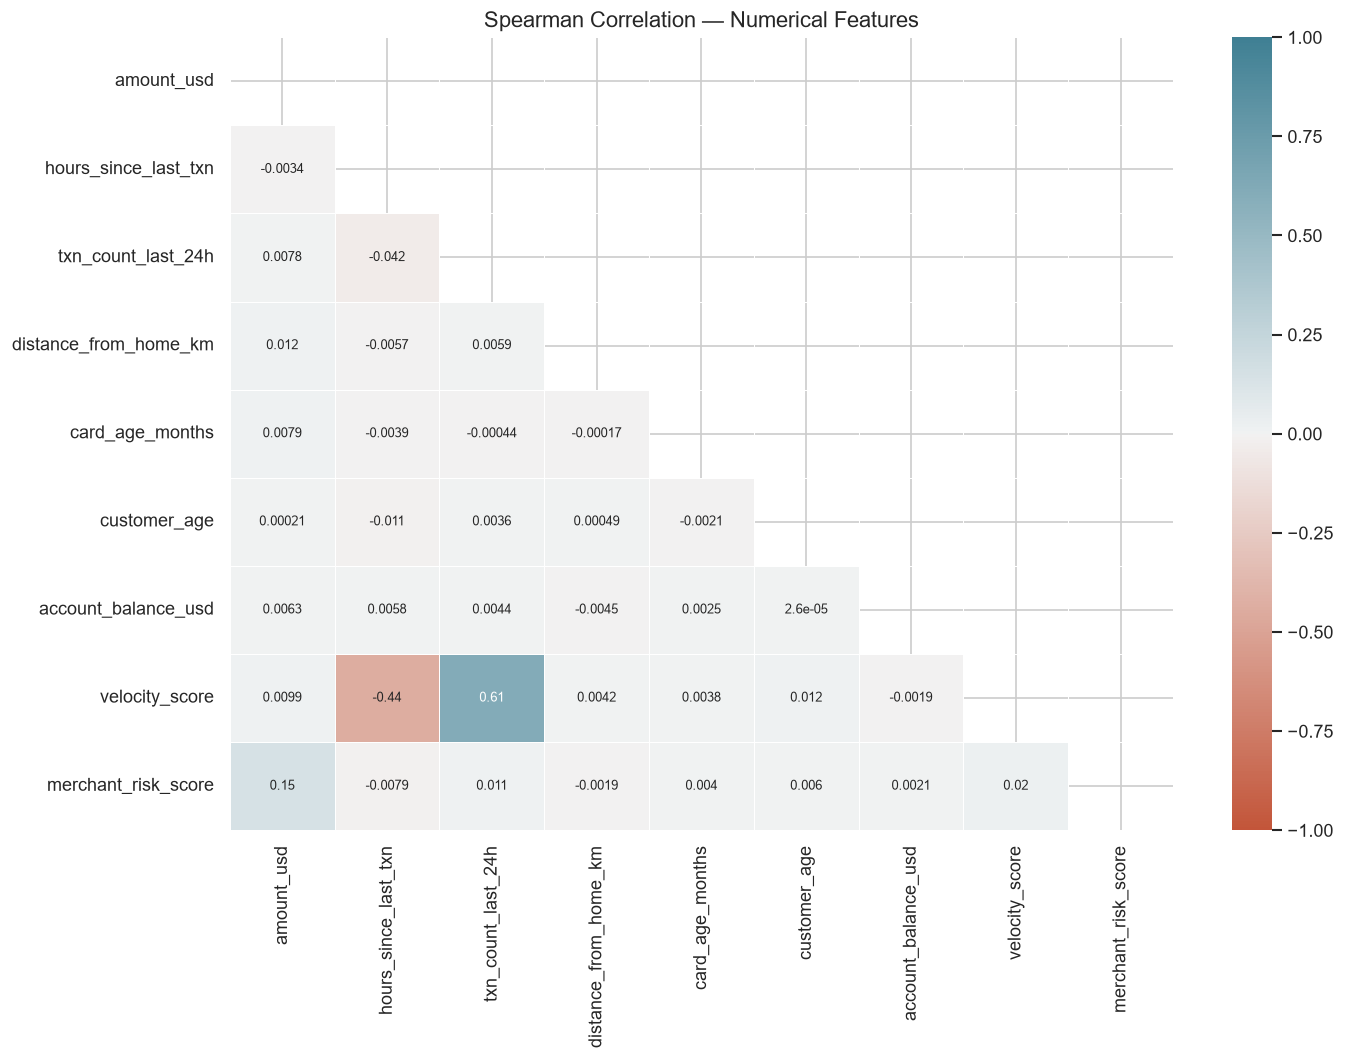

In [20]:
spearman_excluded_cols = [
    "time_of_day_hour",
    "day_of_week",
    "cvv_retry_count",
    "prior_disputes"
]

def heat_of(corr, corr_type: str):
    mask = np.zeros_like(corr)
    mask[np.triu_indices_from(mask)] = True

    plt.figure(figsize=(12, 9))
    sns.heatmap(
        corr,
        vmax=1, vmin=-1,
        annot=True,
        annot_kws={'fontsize': 8},
        mask=mask,
        cmap=sns.diverging_palette(20, 220, as_cmap=True),
        linewidths=0.5
    )
    plt.title(f"{corr_type} Correlation — Numerical Features", fontsize=13)
    plt.tight_layout()
    plt.show()

spearman_cols = [c for c in num_cols if c not in spearman_excluded_cols]
spearman_corr = df_train[spearman_cols].corr(method="spearman")
heat_of(spearman_corr, "Spearman")

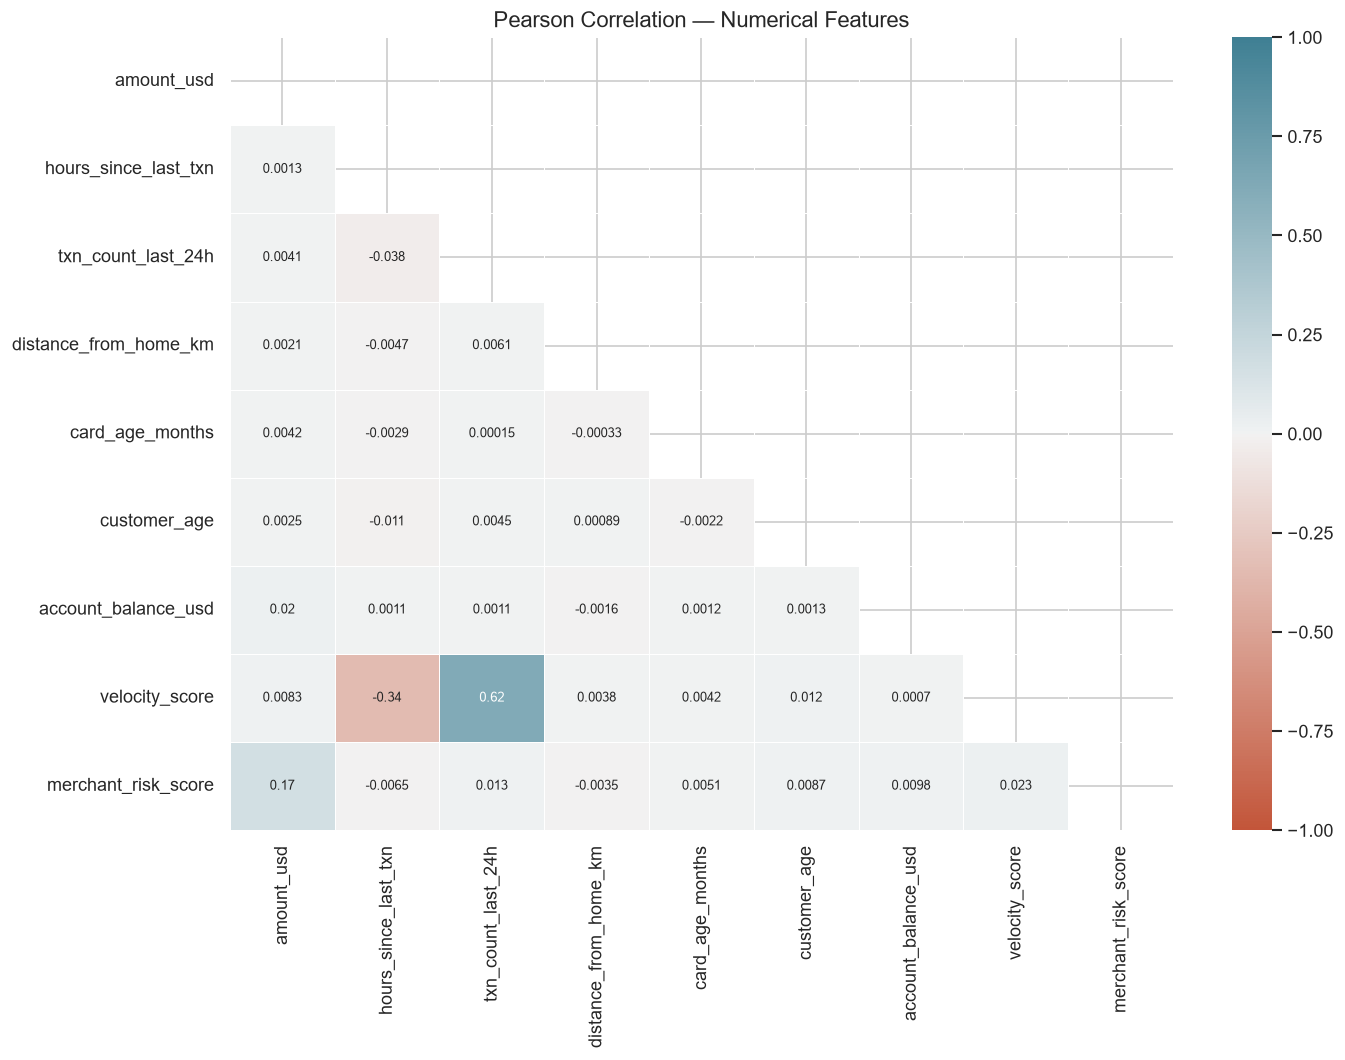

In [21]:
pearson_corr = df_train[spearman_cols].corr()
heat_of(pearson_corr, "Pearson")

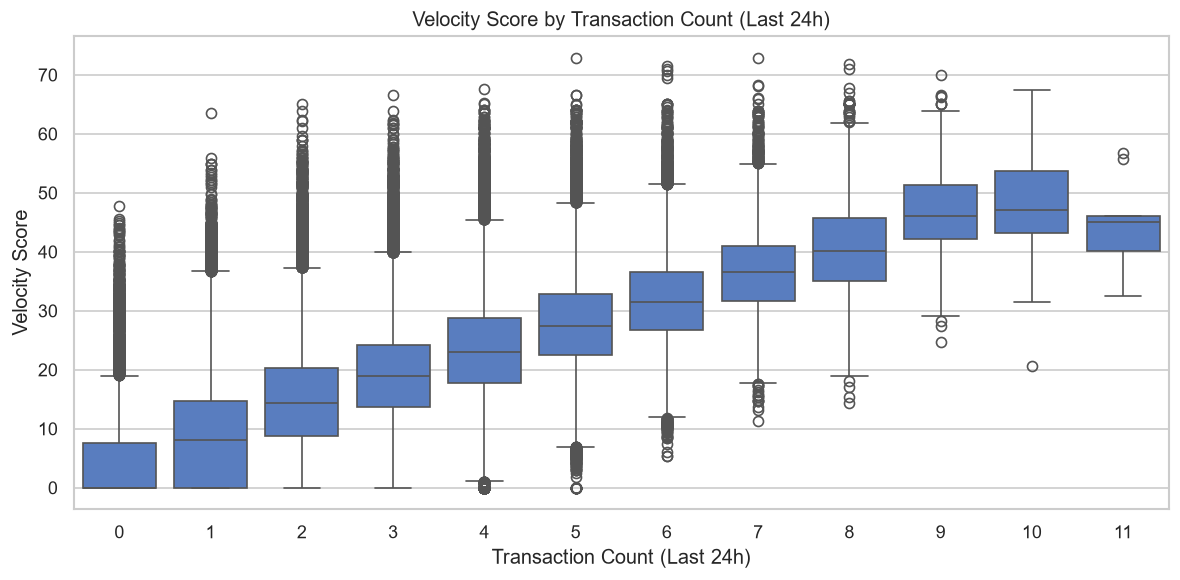

In [22]:
# txn_count_last_24 -- velocity_score

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_train,
    x="txn_count_last_24h",
    y="velocity_score"
)

plt.title("Velocity Score by Transaction Count (Last 24h)")
plt.xlabel("Transaction Count (Last 24h)")
plt.ylabel("Velocity Score")
plt.tight_layout()
plt.show()

In [31]:
df_train.groupby("txn_count_last_24h")["id"].agg("count")

txn_count_last_24h
0      18462
1      92705
2     170757
3     178367
4     131869
5      69701
6      26488
7       8907
8       2252
9        378
10        65
11         9
Name: id, dtype: int64

Median velocity increases with transaction count.  
The spread does not show a consistent increasing pattern as transaction count rises.  
High transaction counts are relatively rare (5.44% of transactions have a count greater than 5).  

-> INSIGHT: Transaction freq and velocity score show **positive association**:  
velocity score tends to increase with the number of txn in the last 24h, while the distribution's spread does not show a clear, consistent expansion

## 7. Correlation Analysis of Categorical Features

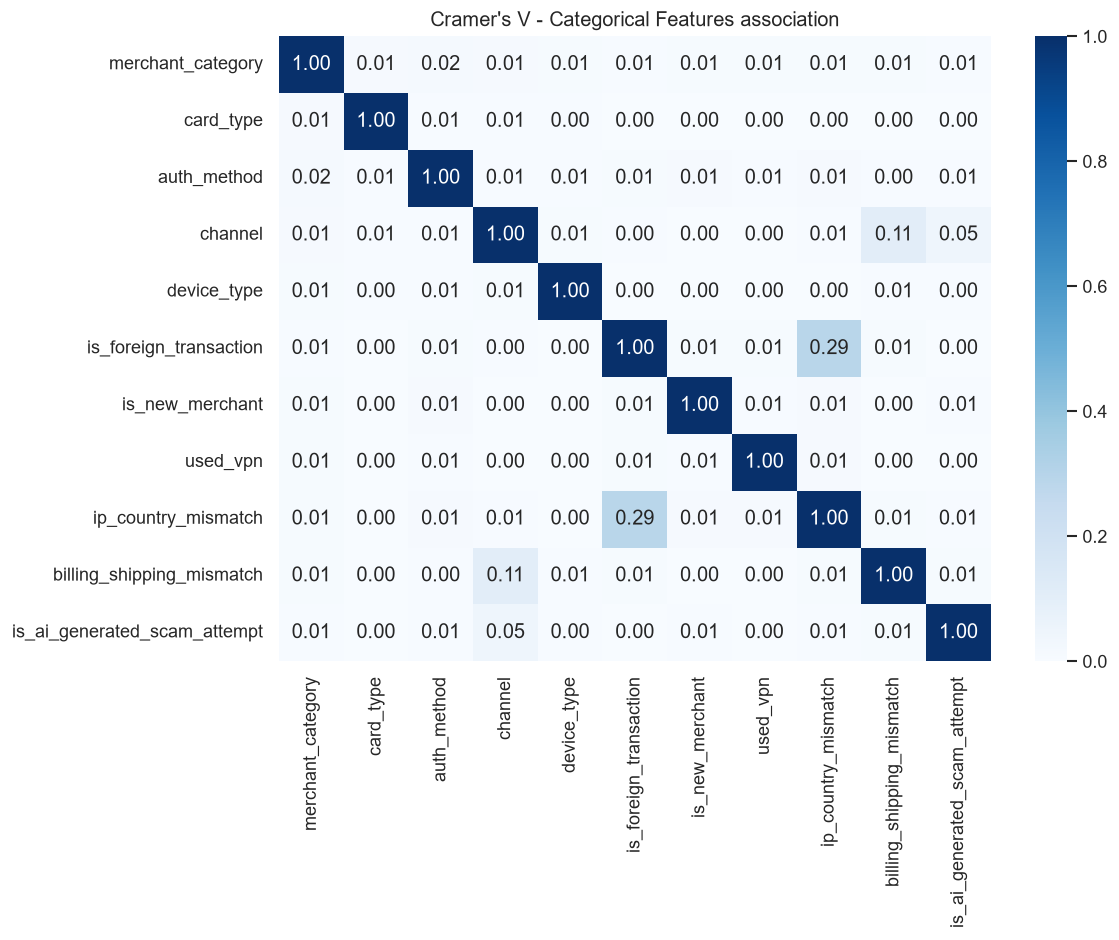

In [23]:
# using cramer-V to see the strength (but not include direction) of
# association between categorical features

def cramers_v(x, y):
    table = pd.crosstab(x, y)

    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    r, c = table.shape

    return np.sqrt(chi2 / (n * min(r-1, c-1)))

# association matrix for categorical features
association_cols = cat_cols + bool_cols

cramers_matrix = pd.DataFrame(
    index=association_cols,
    columns=association_cols,
    dtype=float
)

for col1 in association_cols:
    for col2 in association_cols:
        cramers_matrix.loc[col1, col2] = cramers_v(
            df_train[col1],
            df_train[col2]
        )

# Visualize it
plt.figure(figsize=(10,8))

sns.heatmap(
    cramers_matrix, 
    vmin=0, vmax=1, 
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.title("Cramer's V - Categorical Features association")
plt.tight_layout()
plt.show()

MOST noticeable pairs:  
`ip_country_mismatch` & `is_foreign_transaction`  (0.29)

But is not interesting enough.  
each feature convey different meaning, hardly any overlap  
Should not be considered associated.

### 8. Mixed Correlation Analysis

In [40]:
# See them again
print(f"Numerical columns: ({len(num_cols)}): {num_cols}")
print(f"Categorical columns: ({len(cat_cols)}): {cat_cols}")
print(f"Binary columns: ({len(bool_cols)}): {bool_cols}")

Numerical columns: (13): ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']
Categorical columns: (5): ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
Binary columns: (6): ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


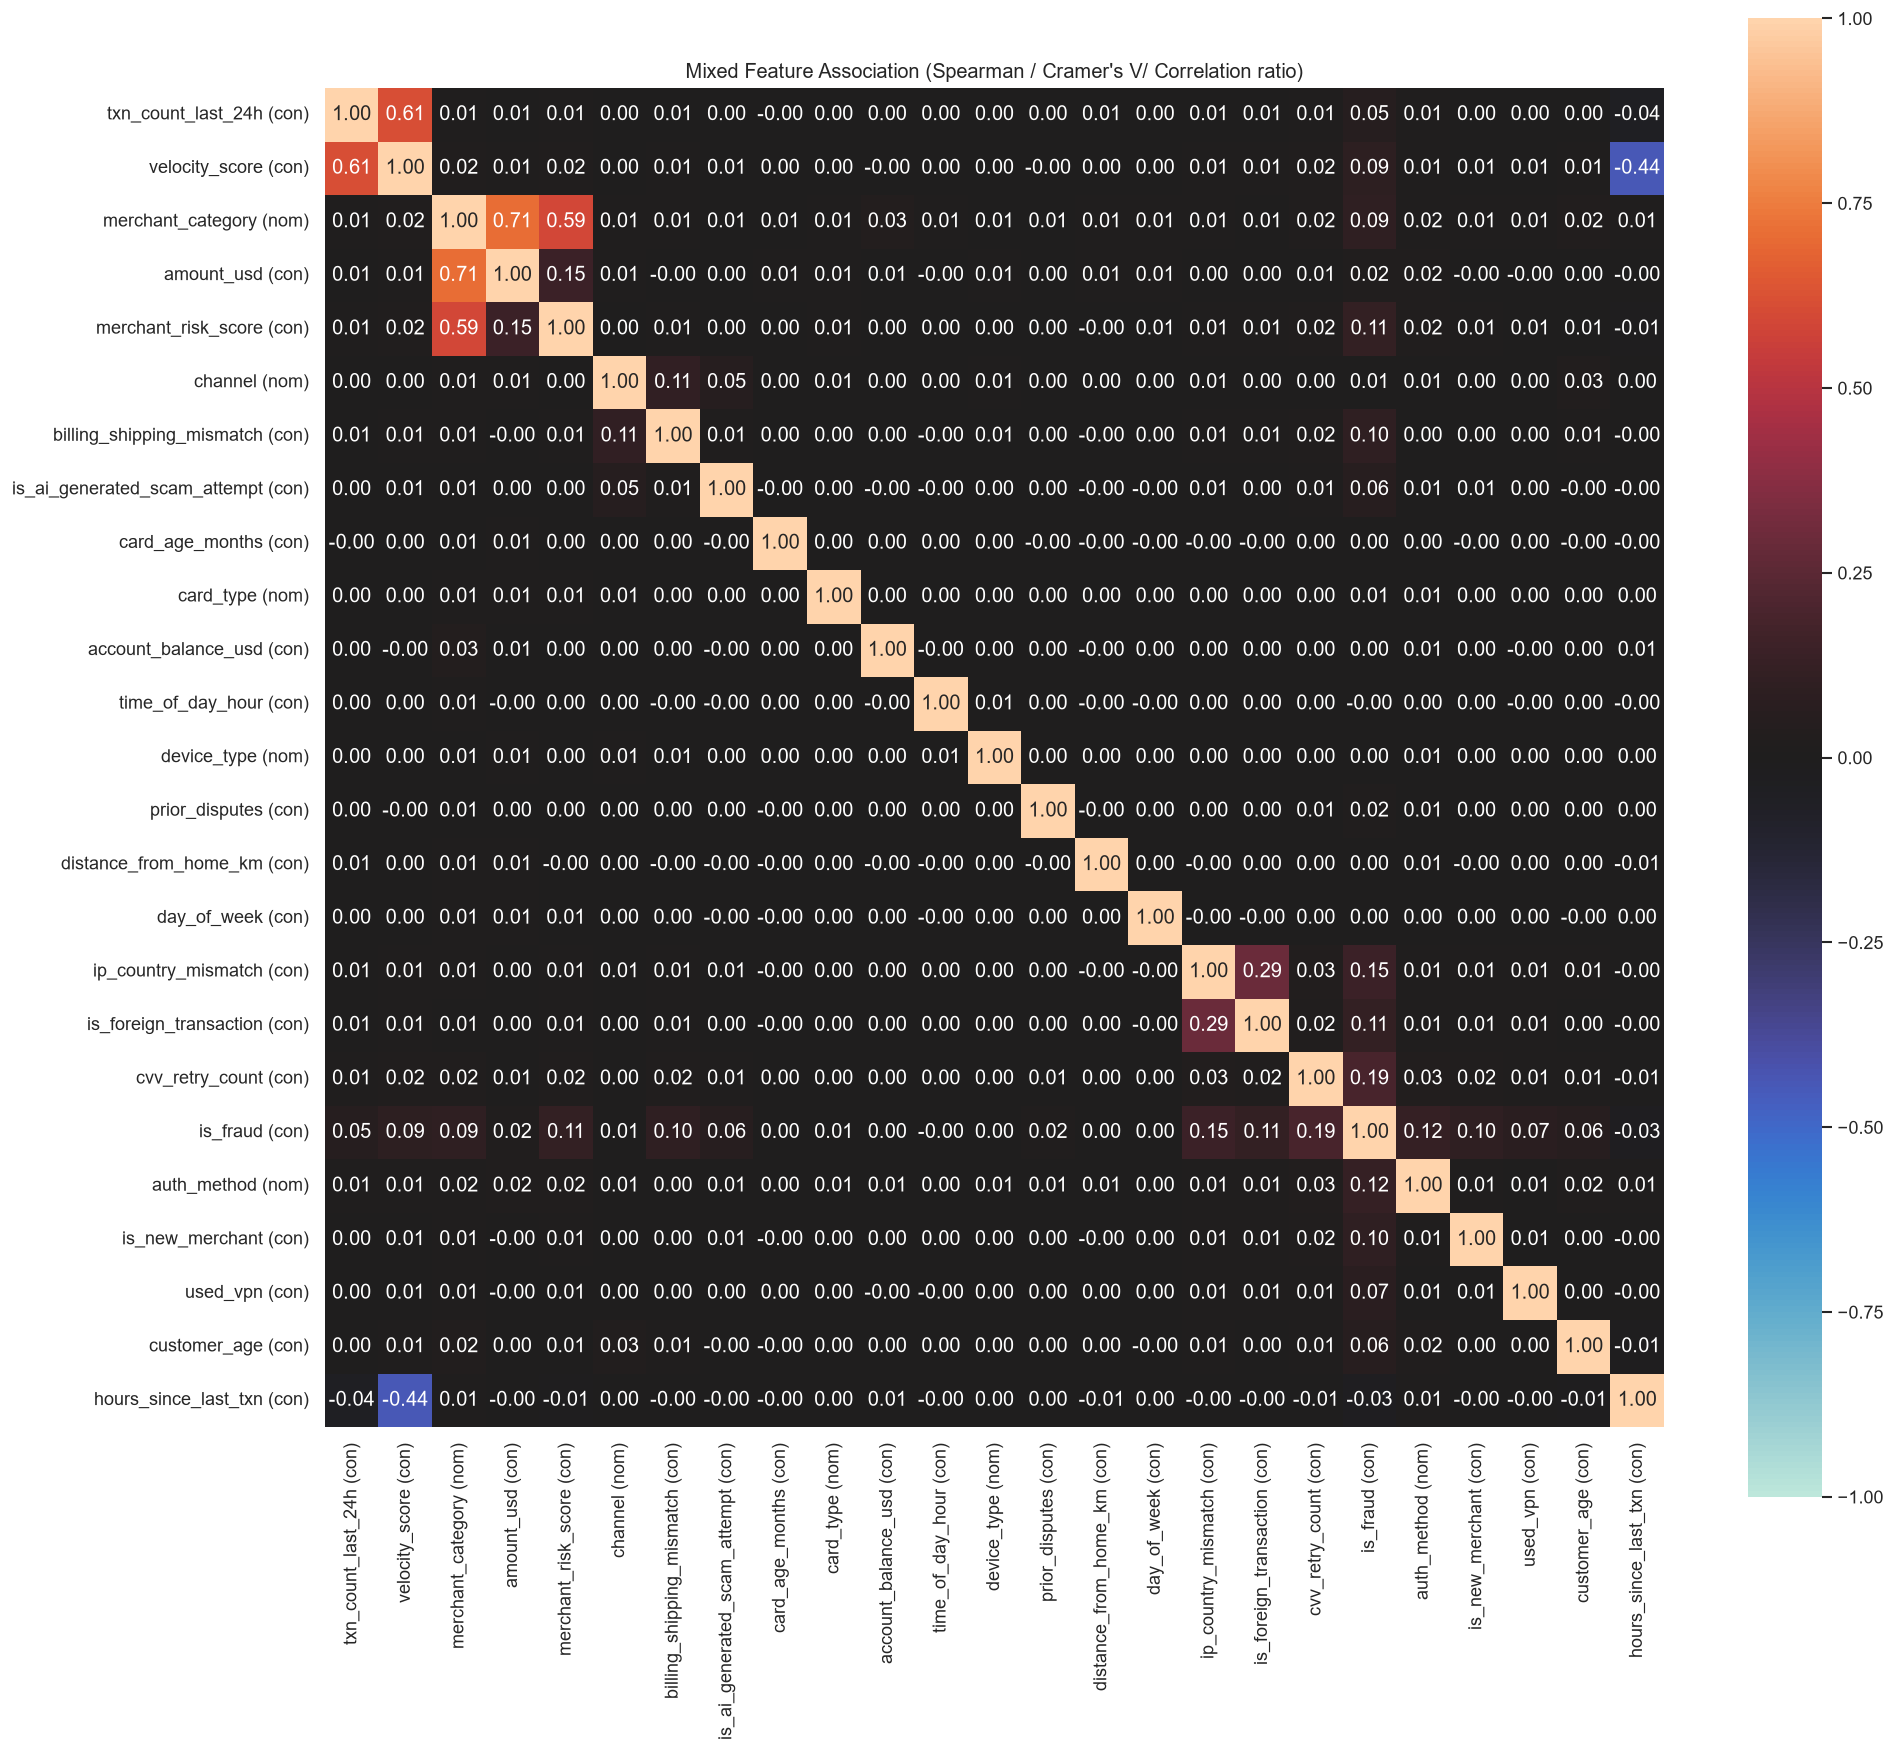

<Figure size 768x576 with 0 Axes>

In [ ]:
df_assoc = df_train.drop(columns=["id"])

# workaround
import scipy.cluster.hierarchy
import scipy.spatial.distance
scipy.cluster.hierarchy.distance = scipy.spatial.distance

associations(
    df_assoc,
    figsize=(18, 16),
    mark_columns=True,
    clustering=True,
    num_num_assoc="spearman",
    title="Mixed Feature Association (Spearman / Cramer's V/ Correlation ratio)"
)

plt.tight_layout()
plt.show()


Some num-cat pairs that may have meaning:
```
amount_usd - merchant_category
merchant_risk_score - merchant_category
```

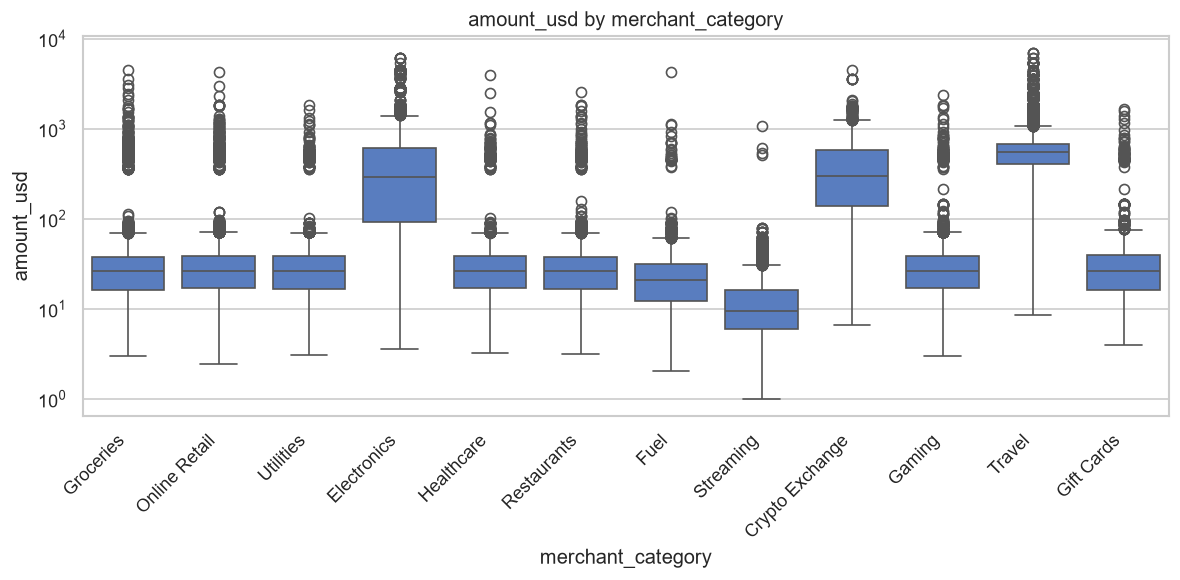

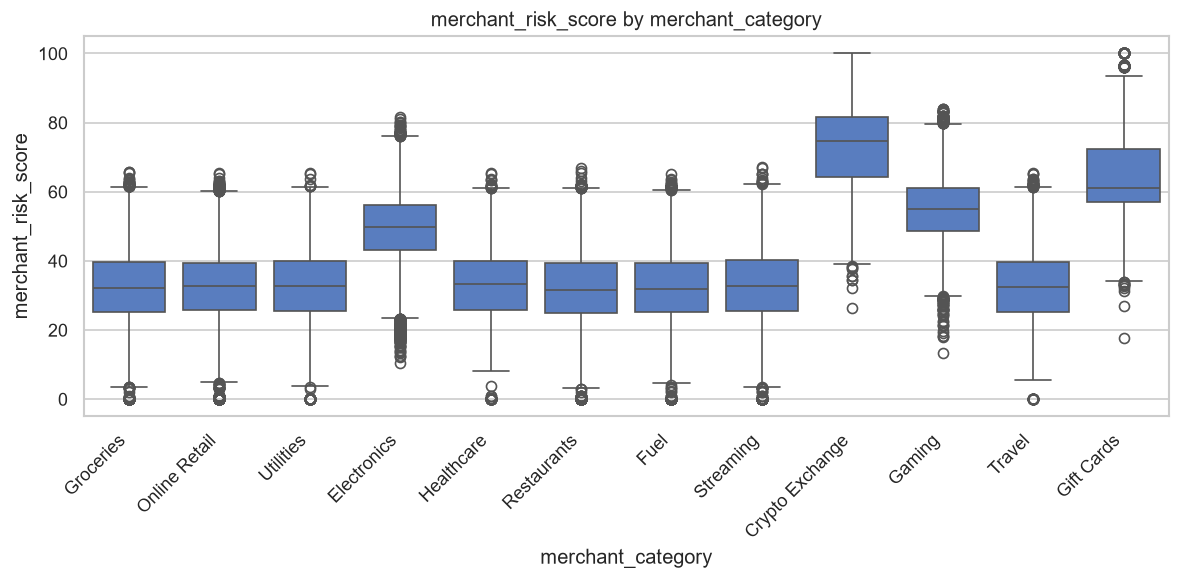

In [26]:
mixed_pairs = [
    ("amount_usd", "merchant_category"),
    ("merchant_risk_score", "merchant_category")
]

for num_feature, cat_feature in mixed_pairs:
    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df_train,
        x=cat_feature,
        y=num_feature
    )
    if (num_feature == "amount_usd"):
        plt.yscale("log")
    plt.title(f"{num_feature} by {cat_feature}")
    plt.xlabel(cat_feature)
    plt.ylabel(num_feature)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

From two diagrams:  
- some categories show differences in median values and also distribution spread
- but distribution overlap exist across the numerical distributions  

-> No clear association pattern can be infer from these diagrams alone.

## 9. Key findings


#### 9.1 Target Characteristics

- The dataset exhibits a significant class imbalance, with fraudulent transactions accounting for approximately **1.67%** of all transactions.
- Consequently, accuracy alone would be insufficient to evaluate a fraud detection model, as a model predicting every transaction as non-fraud would achieve high accuracy while failing to detect fraud.
- Model evaluation should therefore consider metrics that capture fraud detection performance, particularly Recall, Precision, F1-score, and PR-AUC.

#### 9.2 Numerical Features

- Several numerical features exhibit skewed distributions and extreme values, particularly `amount_usd` and `account_balance_usd`.
- The distributions of fraudulent and non-fraudulent transactions overlap substantially for some features, indicating limited separability when considered individually.
- Individual numerical features exhibit varying degrees of predictive signal, as observed through univariate AUC analysis. However, no single feature should be assumed sufficient for reliable fraud detection.

#### 9.3 Categorical & Boolean Features

- Fraud rates vary considerably across merchant categories. Categories such as Gift Cards, Crypto Exchange, and Gaming exhibit notably higher fraud rates than the overall baseline.
- The `auth_method` category `no auth` also exhibits an elevated fraud rate.
- Transactions with multiple red flags tend to have higher fraud rates. However, a considerable proportion of fraudulent transactions occur without any red flags, indicating that individual flags or simple rule-based approaches may not capture all fraudulent activities.

#### 9.4 Feature Relationships

- `txn_count_last_24h` and `velocity_score` exhibit a positive association. Median velocity scores increase with transaction count, although the spread does not show a consistent increasing pattern.
- `hours_since_last_txn` and `velocity_score` exhibit a negative association.
- Most numerical feature pairs show little evidence of a meaningful monotonic association.
- `is_foreign_transaction` and `ip_country_mismatch` exhibit a notable association (Cramér's V = 0.29), reflecting related geographical transaction characteristics.
- Transaction amounts and merchant risk scores vary across merchant categories. However, substantial overlap remains between numerical distributions, and no clear association pattern could be established from the visualizations alone.

#### 9.5 Modeling Implications

- Given the severe class imbalance, model evaluation should prioritize fraud detection performance rather than accuracy alone.
- Fraud signals are distributed across multiple features, suggesting that combining signals may be more effective than relying on individual features or simple rules.
- Although some features exhibit association with one another, the EDA does not provide sufficient evidence to remove features solely based on correlation.
- The predictive value of individual features and their combined contribution should be evaluated during model development and validation.